# Sprint 1: data cleaning and validation (preprocessing)

**Parfois product similarity, MADSAD case study (FEP, University of Porto).**

This notebook documents the preprocessing done in Sprint 1, from the two raw CSV files to a clean table with one row
per product colourway. Every automatic step is **written out here** with pandas, NumPy and Pillow, so it can be read
and re-run on its own. Two steps were not automatic and are **described, not redone**:

- the **AI image audit** (CLIP, about 1.5 h on a laptop CPU): its results were saved once and are only loaded here;
- the **manual review** by the five team members (photos, colours, categories): its decisions were saved in a change
  log, which is loaded and applied here.

| Step | Section |
|---|---|
| Load and normalise the raw CSVs | 1–2 |
| Profile missing values and duplicates | 3 |
| Collapse sizes (SKUs) into colourways, join sales | 4 |
| Link each colourway to its photo | 5 |
| Automatic quality checks | 6 |
| AI image audit (results only) | 7 |
| Manual review (described; change log applied) | 8 |
| Final cleaning | 9 |
| Result and checks | 10 |

The notebook writes no file.

In [1]:
import hashlib
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_DIR, IMG_DIR = ROOT / "data" / "csv", ROOT / "data" / "images"
KEY = "PROD_CLR_EQUIV"  # model + colour: the unit of analysis

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. The raw data

Two files from Parfois: `df_product.csv` has one row per **SKU** (a size of a product in one colour) and
`df_sales.csv` one row per **colourway**. We first read them exactly as they are.

In [2]:
raw_prod = pd.read_csv(CSV_DIR / "df_product.csv", dtype=str, encoding="utf-8", low_memory=False)
raw_sales = pd.read_csv(CSV_DIR / "df_sales.csv", encoding="utf-8")
print(f"df_product: {raw_prod.shape[0]:,} rows x {raw_prod.shape[1]} columns")
print(f"df_sales:   {raw_sales.shape[0]:,} rows x {raw_sales.shape[1]} columns")
print(f"SKUs: {raw_prod['PROD_COD'].nunique():,} | colourways: {raw_prod[KEY].nunique():,} "
      f"| models (PROD_REF): {raw_prod['PROD_REF'].nunique():,}")
raw_prod[[KEY, "PROD_COD", "SZ_DES", "PROD_DES", "CLR_DES", "CAT_DES_EN", "GFA_DES_EN", "COMPOSITION",
          "PRICE_BASE_W_VAT", "PROG_IMAGE"]].head(6)

df_product: 17,125 rows x 141 columns
df_sales:   10,185 rows x 3 columns
SKUs: 17,125 | colourways: 10,555 | models (PROD_REF): 7,644


,PROD_CLR_EQUIV,PROD_COD,SZ_DES,PROD_DES,CLR_DES,CAT_DES_EN,GFA_DES_EN,COMPOSITION,PRICE_BASE_W_VAT,PROG_IMAGE
0,212013_GD,212013_GDU,U,Earring GLDN DEL Gold U,Gold,Jewellery,Earrings,Acrylic Pearl Thermoplastic Polyurethane Zinc,8.99,/232/52/212013_GD_1
1,212022_GD,212022_GDU,U,Earring GLDN DEL Gold U,Gold,Jewellery,Earrings,Iron,8.99,/232/52/212022_GD_1
2,218792_PM,218792_PML,L,Ring NILE Pastel Multicolor L,Pastel Multicolor,Jewellery,Rings,Resin Zinc,5.99,/241/52/218792_PM_1
3,218792_PM,218792_PMM,M,Ring NILE Pastel Multicolor M,Pastel Multicolor,Jewellery,Rings,Resin Zinc,5.99,/241/52/218792_PM_1
4,211377_BM,211377_BMU,U,Kimono ESSENTIALS T DISPLAY 1 Bright Multicolor U,Bright Multicolor,Apparel,Kimono,Viscose,29.99,/232/64/211377_BM_1
5,206908_GD,206908_GDU,U,Necklace GLDN DEL Gold U,Gold,Jewellery,Necklaces,Brass Pearl,9.99,/231/52/206908_GD_2y


**The unit of analysis is the colourway** (`PROD_CLR_EQUIV`, e.g. `167718_BU`): the description, colour, category
and photo are the same for every size, and the brief asks for similar *products*, not sizes.

A first look at the text shows three problems: non-breaking spaces, padding, and materials separated by double spaces.

In [3]:
text_cols = [c for c in raw_prod.columns if pd.api.types.is_string_dtype(raw_prod[c])]
nbsp = {c: int(raw_prod[c].str.contains("\xa0", regex=False).sum()) for c in text_cols}
print("non-breaking spaces (\\xa0):", {c: n for c, n in nbsp.items() if n})
pad = pd.Series({c: int((raw_prod[c].notna() & (raw_prod[c].str.strip() != raw_prod[c])).sum()) for c in text_cols})
pad = pad[pad > 0].sort_values(ascending=False)
print(f"leading/trailing spaces in {len(pad)} columns, the most affected:", pad.head(6).to_dict())
print("\nCOMPOSITION separates materials with double spaces:")
print(raw_prod["COMPOSITION"].dropna().head(3).map(repr).to_string())

non-breaking spaces (\xa0): {'PROD_DES': 136, 'GFA_DES_PT': 136, 'GFA_DES_EN': 136, 'GFS_DES_PT': 21, 'GFS_DES_EN': 21, 'DESCRIPTION': 90, 'L4_DES': 136}


leading/trailing spaces in 7 columns, the most affected: {'COMPOSITION': 17124, 'MAIN_THEME': 785, 'THEME': 201, 'THEME_ASIS': 201, 'GFA_DES_PT': 136, 'GFA_DES_EN': 136}

COMPOSITION separates materials with double spaces:
0    ' Acrylic  Pearl  Thermoplastic Polyurethane  ...
1                                              ' Iron'
2                                       ' Resin  Zinc'


## 2. Loading and normalising

- Codes are read as **strings**, so leading zeros survive (`CAT_COD` `"052"` must not become `52`).
- Every text column: `\xa0` → space, trimmed, repeated spaces collapsed.
- `COMPOSITION` becomes a canonical list: `"Zinc  Enamel"` and `"Enamel  Zinc"` both become `"Enamel; Zinc"`.

In [4]:
STR_DTYPES = {c: str for c in ["PROD_REF", "PROD_REF_EQUIV", "BAR_COD", "SEA_COD", "CAT_COD", "GFA_COD", "GFS_COD",
                               "SUP_COD", "TARIFF_COD"]}

def normalise_text(s):
    return s.str.replace("\xa0", " ", regex=False).str.strip().str.replace(r"\s+", " ", regex=True)

prod = pd.read_csv(CSV_DIR / "df_product.csv", dtype=STR_DTYPES, encoding="utf-8", low_memory=False)
sales = pd.read_csv(CSV_DIR / "df_sales.csv", encoding="utf-8")
prod["COMPOSITION"] = prod["COMPOSITION"].str.strip().str.replace(r"\s{2,}", "; ", regex=True)
for col in prod.columns:
    if pd.api.types.is_string_dtype(prod[col]):
        prod[col] = normalise_text(prod[col])
prod["COMPOSITION"] = prod["COMPOSITION"].map(
    lambda s: "; ".join(sorted(set(s.split("; ")))) if isinstance(s, str) else s)
sales[KEY] = sales[KEY].str.strip()

before_after = pd.DataFrame({"raw": raw_prod["COMPOSITION"], "clean": prod["COMPOSITION"]}).dropna()
before_after[before_after["raw"] != before_after["clean"]].drop_duplicates().head(5)

,raw,clean
0,Acrylic Pearl Thermoplastic Polyurethane Zinc,Acrylic; Pearl; Thermoplastic Polyurethane; Zinc
1,Iron,Iron
2,Resin Zinc,Resin; Zinc
4,Viscose,Viscose
5,Brass Pearl,Brass; Pearl


## 3. Missing values and duplicates

Each column is labelled **empty** (≥ 99.9% missing), **constant** (one value), **sparse** (≥ 50% missing) or ok.

status
ok                        91
empty                     21
sparse (>=50% missing)    17
constant                  12


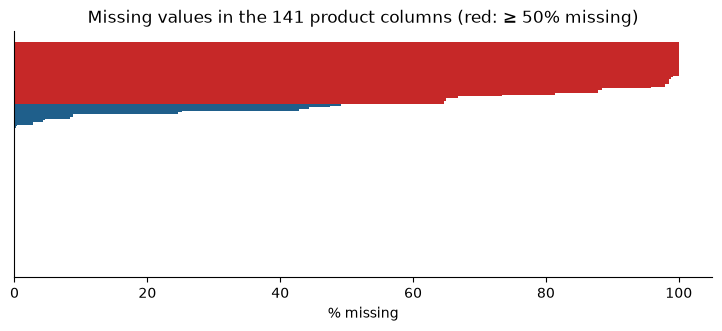

In [5]:
n = len(prod)
miss = pd.DataFrame({"n_missing": prod.isna().sum(), "pct_missing": (prod.isna().mean() * 100).round(2),
                     "n_unique": prod.nunique()})
miss["status"] = "ok"
miss.loc[miss["pct_missing"] >= 50, "status"] = "sparse (>=50% missing)"
miss.loc[miss["n_unique"] <= 1, "status"] = "constant"
miss.loc[miss["n_missing"] >= n * 0.999, "status"] = "empty"
miss = miss.sort_values("pct_missing", ascending=False)
print(miss["status"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(9, 3.2))
pct = miss["pct_missing"].sort_values()
ax.barh(range(len(pct)), pct.to_numpy(), color=np.where(pct >= 50, "#c62828", "#1f5f8b"), height=1.0)
ax.set_yticks([])
ax.set_xlabel("% missing")
ax.set_title(f"Missing values in the {len(pct)} product columns (red: ≥ 50% missing)")
plt.show()

In [6]:
prod_keys, sales_keys = set(prod[KEY]), set(sales[KEY])
pd.Series({
    "product: fully duplicated rows": prod.duplicated().sum(),
    "product: duplicated SKU code (PROD_COD)": prod["PROD_COD"].duplicated().sum(),
    "product: duplicated barcode (BAR_COD)": prod["BAR_COD"].duplicated().sum(),
    "product: duplicated PROD_COD_EQUIV (re-coded items, expected)": prod["PROD_COD_EQUIV"].duplicated().sum(),
    "sales: duplicated keys": sales[KEY].duplicated().sum(),
    "sales: keys not in the product table": len(sales_keys - prod_keys),
    "product: colourways without sales": len(prod_keys - sales_keys),
}, name="count").to_frame()

,count
product: fully duplicated rows,0
product: duplicated SKU code (PROD_COD),0
product: duplicated barcode (BAR_COD),0
"product: duplicated PROD_COD_EQUIV (re-coded items, expected)",28
sales: duplicated keys,0
sales: keys not in the product table,0
product: colourways without sales,370


No real duplicates; re-coded items (`*_EQUIV`) repeat by design. Every sales row has a product, and 370 colourways
have no sales (new or never sold), so sales are joined with a **left join**.

## 4. From SKUs to colourways

- One row per colourway, with the list of sizes and a size-free description (`PROD_DES_BASE`:
  `"Earring ESSENTIALS Gold U"` → `"Earring ESSENTIALS Gold"`).
- Attributes used for similarity must be **the same for every size**. Where sizes disagree, the most common value is
  kept and the conflict recorded in `sku_conflicts` (flag `SKU_ATTR_CONFLICT`) for the review, instead of silently
  taking the first size.
- Sales are joined (left join).

In [7]:
SKU_INVARIANT = ["CLR_COD", "CLR_DES", "CLR_TYPE", "CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN", "CATEGORY_MATRIX",
                 "COMPOSITION", "MATERIAL", "FINISHING", "PRINT_TYPE", "OUTFIT", "DIMENSION", "NUMBER_OF_UNITS",
                 "THEME", "FASHIONTYPE", "PROD_SEG", "PRICE_BASE_W_VAT", "PROG_IMAGE"]

p = prod.copy()
p["PROD_DES_BASE"] = [d[: -len(sz) - 1] if isinstance(d, str) and isinstance(sz, str) and d.endswith(" " + sz) else d
                      for d, sz in zip(p["PROD_DES"], p["SZ_DES"])]
g = p.groupby(KEY, sort=True)
items = g.first()

varies = g[SKU_INVARIANT].nunique(dropna=False) > 1
items["sku_conflicts"] = varies.apply(lambda r: "|".join(r.index[r]), axis=1)
conflicted = varies.index[varies.any(axis=1)]
modes = p[p[KEY].isin(conflicted)].groupby(KEY)[SKU_INVARIANT].agg(lambda s: s.mode(dropna=False).iat[0])
items.loc[modes.index, SKU_INVARIANT] = modes

# a re-coded colourway owns SKUs of an old and a new model code: keep both
refs = pd.concat([p[[KEY, c]].set_axis([KEY, "ref"], axis=1) for c in ["PROD_REF", "PROD_REF_EQUIV"]])
items["refs_all"] = refs.dropna().drop_duplicates().groupby(KEY)["ref"].agg(lambda s: "|".join(sorted(s)))
items["n_skus"] = g.size()
items["sizes"] = g["SZ_DES"].agg(lambda s: "|".join(s.dropna().unique()))
items = items.reset_index().merge(sales, on=KEY, how="left")
items["issues"] = ""

print(f"{len(prod):,} SKUs -> {len(items):,} colourways (key unique: {items[KEY].is_unique})")
print(f"sales joined: {items['SALES_QTY'].notna().sum():,} of {len(sales):,} rows; "
      f"{items['SALES_QTY'].isna().sum()} colourways without sales")
items[[KEY, "PROD_DES_BASE", "sizes", "n_skus", "SALES_QTY"]].sample(5, random_state=1)

17,125 SKUs -> 10,555 colourways (key unique: True)
sales joined: 10,185 of 10,185 rows; 370 colourways without sales


,PROD_CLR_EQUIV,PROD_DES_BASE,sizes,n_skus,SALES_QTY
5382,217485_HM,Necklace FLEURSDUMER Halftone Multicolor,U,1,3162.0
4625,216352_RD,Cardigan REMY 4 Red,M/L|XS/S,2,1.0
7864,222304_PK,Trainer Shoes RUNNING PINK Pink,37|38|36|40|41|39,6,498.0
391,204741_IV,Key Chain FASHION SUPPLEMENTS Ivory,U,1,7697.0
2621,212561_RD,Earring EXPEDITION Red,U,1,2607.0


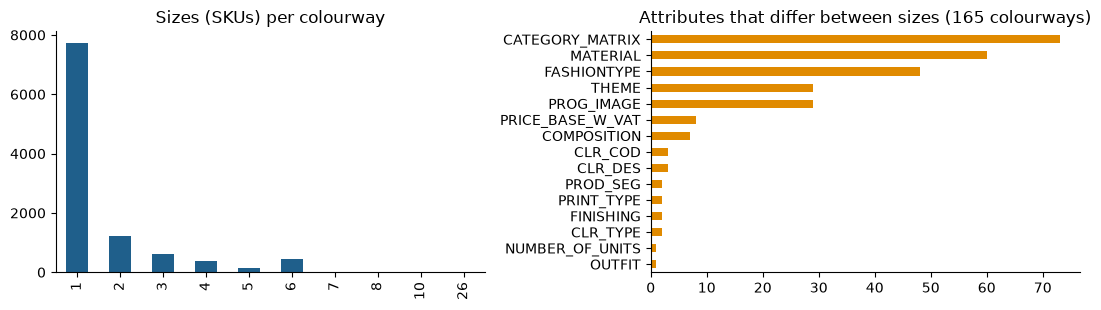

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
items["n_skus"].value_counts().sort_index().plot.bar(ax=axes[0], color="#1f5f8b")
axes[0].set_title("Sizes (SKUs) per colourway")
axes[0].set_xlabel("")
conf = items["sku_conflicts"].str.split("|").explode().loc[lambda s: s != ""].value_counts()
conf.plot.barh(ax=axes[1], color="#e08a00")
axes[1].set_title(f"Attributes that differ between sizes ({(items['sku_conflicts'] != '').sum()} colourways)")
axes[1].set_ylabel("")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Linking each colourway to its photo

`PROG_IMAGE` looks like `/241/52/167718_BU_1`: season, category code, file name without extension. The photo is
linked through that **file stem**, never by building a file name from the product code (some names are irregular).

Repair: some paths drop the colour (`/242/52/212983_2`) while the file has it (`212983_HM_1.jpg`). An item without a
file is linked to an unused file named after it, only if that file is unambiguous (one candidate, one claimant).

In [9]:
def add_issue(mask, code):
    items.loc[mask.fillna(False).astype(bool), "issues"] += code + ";"

parts = items["PROG_IMAGE"].str.extract(r"^/(?P<season>[^/]+)/(?P<cat>\d{2})/(?P<stem>[^/]+)$")
items["img_stem"] = parts["stem"].str.rstrip(".")
path_ok = parts["stem"].notna() & parts["season"].str.fullmatch(r"\d{3}").fillna(False)
add_issue(~path_ok & items["PROG_IMAGE"].notna(), "IMG_PATH_INVALID")

files = {os.path.splitext(f)[0]: f for f in os.listdir(IMG_DIR)}
items["img_file"] = items["img_stem"].map(files)

# repair: unused files that start with the item's code + "_"
orphans = [s for s in files if s not in set(items["img_stem"].dropna())]
claims = {}
for i, r in items[items["img_file"].isna()].iterrows():
    codes = {c for c in (r[KEY], r["PROD_CLR"]) if isinstance(c, str)}
    cands = [o for o in orphans if any(o.startswith(c + "_") for c in codes)]
    if len(cands) == 1:
        claims[i] = cands[0]
owners = pd.Series(list(claims.values()), dtype="object").value_counts()
repaired = pd.Series(False, index=items.index)
for i, stem in claims.items():
    if owners[stem] == 1:
        items.at[i, "img_file"], items.at[i, "img_stem"], repaired[i] = files[stem], stem, True

items["has_image"] = items["img_file"].notna()
add_issue(~items["has_image"], "IMG_FILE_MISSING")
add_issue(repaired, "IMG_PATH_REPAIRED")
used = set(items["img_file"].dropna())
print(f"image files: {len(files):,} | colourways with a photo: {items['has_image'].sum():,} of {len(items):,} "
      f"({items['has_image'].mean():.1%}) | repaired: {repaired.sum()} | files left unused: {len(set(files.values()) - used)}")

image files: 9,496 | colourways with a photo: 9,491 of 10,555 (89.9%) | repaired: 33 | files left unused: 18


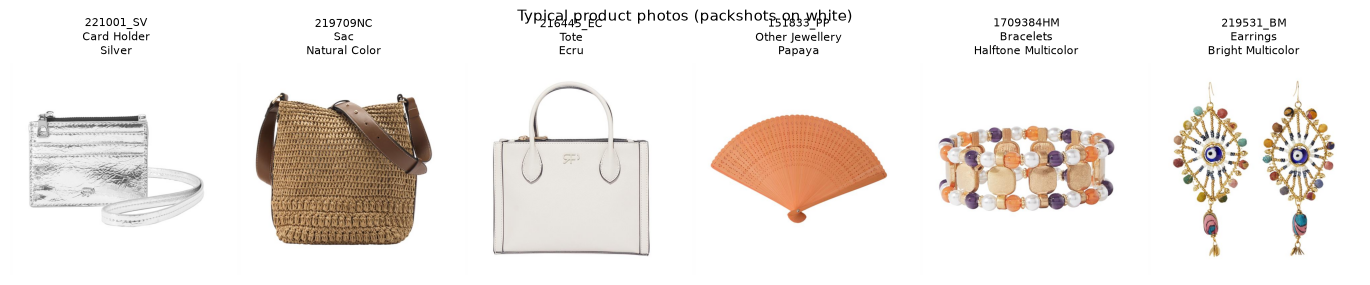

In [10]:
def show(keys, title, table=None, n=6):
    rows = (items if table is None else table).set_index(KEY).loc[list(keys)[:n]]
    fig, axes = plt.subplots(1, len(rows), figsize=(2.3 * len(rows), 2.9))
    for ax, (k, r) in zip(np.atleast_1d(axes), rows.iterrows()):
        if isinstance(r.get("img_file"), str):
            ax.imshow(Image.open(IMG_DIR / r["img_file"]).convert("RGB"))
        ax.set_title(f"{k}\n{r['GFA_DES_EN']}\n{r['CLR_DES']}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()

show(items.loc[items["has_image"], KEY].sample(6, random_state=3), "Typical product photos (packshots on white)")

The 18 files left unused are not broken links. Each belongs to a colourway whose sizes list **different photos**
(mostly re-coded items, with SKUs under an old and a new model code). A colourway uses the photo most of its sizes
list, so the others are not needed. All 18 colourways are flagged `SKU_ATTR_CONFLICT`, so the review looked at them.

## 6. Automatic quality checks

Each check adds an **issue code** with a severity. Nothing is changed or dropped here: the flags decide what the
manual review looks at first.

| Severity | Meaning |
|---|---|
| high | two sources contradict each other: must be reviewed |
| medium | probably a problem: should be reviewed |
| low | worth a look |
| info | a note (e.g. no photo, no sales): the item is kept and handled downstream |

### 6.1 Photo files: model, colour, readability, size, re-use

In [11]:
# category folder in the path vs the item's category; file name of another model
add_issue(parts["cat"].notna() & (parts["cat"] != items["CAT_COD"]), "IMG_CAT_MISMATCH")
ref_ok = pd.Series([isinstance(s, str) and any(s.startswith(r) for r in refs.split("|"))
                    for s, refs in zip(items["img_stem"], items["refs_all"])], index=items.index)
add_issue(items["img_stem"].notna() & ~ref_ok, "IMG_REF_MISMATCH")

# colour code in the file name (<ref><colour>_<n>) vs the item's colour code; no colour = generic photo
img_clr = items["img_stem"].str.extract(r"^\d{6}([_\dA-Z]?[A-Z]{2})_")[0]
same = img_clr.str.lstrip("_") == items["CLR_COD"].str.lstrip("_")
add_issue(img_clr.notna() & ~same, "IMG_COLOUR_MISMATCH")
add_issue(items["img_stem"].notna() & img_clr.isna(), "IMG_GENERIC")

# open every photo once: content hash, readable, size and colour mode (~10 s)
md5, readable, shape = {}, {}, {}
for i, f in items["img_file"].dropna().items():
    path = IMG_DIR / f
    md5[i] = hashlib.md5(path.read_bytes()).hexdigest()
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            shape[i] = (im.width, im.height, im.mode)
        readable[i] = True
    except Exception:
        readable[i] = False
items["img_md5"] = pd.Series(md5, dtype="object")
add_issue(pd.Series(readable).reindex(items.index).eq(False), "IMG_UNREADABLE")
shape = pd.DataFrame.from_dict(shape, orient="index", columns=["img_width", "img_height", "img_mode"])
items[shape.columns] = shape
w, h = items["img_width"].astype(float), items["img_height"].astype(float)
add_issue(np.minimum(w, h) < 300, "IMG_SMALL")
add_issue((w / h > 1.5) | (h / w > 1.5), "IMG_ODD_SHAPE")
add_issue(items["img_mode"].notna() & (items["img_mode"] != "RGB"), "IMG_NOT_RGB")

# the same picture (same path or same bytes) used by another colour or model
img_key = items["img_md5"].fillna(items["PROG_IMAGE"])
n_clr = items.groupby(img_key)["CLR_COD"].transform("nunique")
n_ref = items.groupby(img_key)["PROD_REF"].transform("nunique")
add_issue(img_key.notna() & ((n_clr > 1) | (n_ref > 1)), "IMG_SHARED")

sizes = items.loc[items["has_image"]].groupby(["img_width", "img_height"]).size().sort_values(ascending=False)
print("most common photo sizes:", sizes.head(3).to_dict(), "| colour modes:", items["img_mode"].value_counts().to_dict())

most common photo sizes: {(640.0, 640.0): 9097, (479.0, 640.0): 279, (640.0, 480.0): 25} | colour modes: {'RGB': 9490}


### 6.2 Text against codes: colour and item type

- The key must be consistent: `PROD_CLR` = `PROD_REF` + `CLR_COD`.
- The letters of a colour code (`_BK`, `1BK` → `BK`) should always mean the same colour name.
- The description should mention the colour (`"Earring GLDN DEL Gold"`), and must not name *another* colour at its end.
- The first word of the description (the item type: *Necklace*, *Ring*...) is compared with the family. For each type
  word with at least 20 items, a family that covers under 5% of them is a contradiction (e.g. "Necklace ..." filed
  under Earrings), learned from the data itself.

In [12]:
add_issue(items["PROD_CLR"] != items["PROD_REF"] + items["CLR_COD"], "TAB_KEY_INCONSISTENT")

letters = items["CLR_COD"].str.replace(r"^[_\d]", "", regex=True)
majority = items.groupby(letters)["CLR_DES"].agg(lambda s: s.mode().iat[0])
add_issue(items["CLR_DES"] != letters.map(majority), "CLR_CODE_NAME_INCONSISTENT")

colours = sorted(items["CLR_DES"].dropna().unique(), key=len, reverse=True)
def colour_in_desc(desc, clr):
    if not isinstance(desc, str) or not isinstance(clr, str):
        return "missing"
    if clr.lower() in desc.lower():
        return "ok"
    # colour words are Title Case; theme names are upper case ("SILVER BASICS"): match case-sensitively
    return "conflict" if any(desc.endswith(" " + c) for c in colours) else "not_found"
status = pd.Series([colour_in_desc(d, c) for d, c in zip(items["PROD_DES_BASE"], items["CLR_DES"])], index=items.index)
add_issue(status == "conflict", "CLR_CONFLICT_DESC")
add_issue(status == "not_found", "CLR_NOT_IN_DESC")

def singular(word):
    w = word.lower().strip()
    if len(w) <= 3 or not w.endswith("s") or w.endswith(("ss", "us", "is")):
        return w
    if w.endswith("ies") and len(w) > 4:
        return w[:-3] + "y"
    if w.endswith(("sses", "xes", "ches", "shes")):
        return w[:-2]
    return w[:-1]

def type_word(desc):
    if not isinstance(desc, str) or not desc:
        return None
    t = desc.split()
    if t[0].lower() == "set":  # "Set of 3 Rings ..." -> the type comes after
        t = t[2:] if len(t) > 1 and t[1].lower() == "of" else t[1:]
    return singular(t[0]) if t else None

tw = items["PROD_DES_BASE"].map(type_word)
counts = items.assign(tw=tw).groupby(["tw", "GFA_DES_EN"]).size()
totals = counts.groupby(level=0).transform("sum")
stats = pd.DataFrame({"share": counts / totals, "support": totals}).reset_index()
st = items.assign(tw=tw)[["tw", "GFA_DES_EN"]].merge(stats, how="left", on=["tw", "GFA_DES_EN"])
own_named = pd.Series([isinstance(d, str) and isinstance(f, str) and singular(f) in d.lower()
                       for d, f in zip(items["PROD_DES_BASE"], items["GFA_DES_EN"])])
add_issue(pd.Series(((st["support"] >= 20) & (st["share"] < 0.05) & ~own_named).to_numpy(), index=items.index),
          "TYPE_CONFLICT_DESC")
items.loc[items["issues"].str.contains("TYPE_CONFLICT_DESC"), [KEY, "PROD_DES_BASE", "GFA_DES_EN", "GFS_DES_EN"]]

,PROD_CLR_EQUIV,PROD_DES_BASE,GFA_DES_EN,GFS_DES_EN
6937,220697_BK,Sac WOODY1 Black,Tote,Plain PU
8922,224036_GY,Wallet CORDY Grey,Others,Printed Fake Nylon


### 6.3 Sales and prices

Flagged, never changed. The realised price is the sales amount divided by the units sold; amounts mix currencies,
so only extreme ratios (under 0.3× or over 1.5× the list price) are flagged.

In [13]:
num = {c: pd.to_numeric(items[c], errors="coerce") for c in
       ["PRICE_BASE_W_VAT", "PRICE_OUTLET_W_VAT", "PRICE_LCP", "SALES_QTY", "SALES_AMT_FX_RATE"]}
base, qty, amt, cost = num["PRICE_BASE_W_VAT"], num["SALES_QTY"], num["SALES_AMT_FX_RATE"], num["PRICE_LCP"]
items["PRICE_BASE_W_VAT"] = base
add_issue(qty.isna(), "SALES_MISSING")
add_issue(qty == 0, "SALES_ZERO_QTY")
add_issue((qty < 0) | (amt < 0), "SALES_NEGATIVE")
add_issue((qty == 0) & (amt > 0), "SALES_AMT_WITHOUT_QTY")
add_issue(base.isna() | (base <= 0), "PRICE_INVALID")
add_issue(num["PRICE_OUTLET_W_VAT"] > base, "PRICE_OUTLET_ABOVE_BASE")
add_issue(cost.isna() | (cost <= 0), "PRICE_COST_MISSING")
add_issue(cost > base, "PRICE_BELOW_COST")
ratio = (amt / qty).where(qty > 0) / base
add_issue((ratio < 0.3) | (ratio > 1.5), "REALISED_PRICE_ODD")
add_issue(items["sku_conflicts"] != "", "SKU_ATTR_CONFLICT")

profile = items.assign(ratio=ratio).groupby("CAT_DES_EN").agg(
    colourways=(KEY, "size"), with_sales=("SALES_QTY", "count"), units_median=("SALES_QTY", "median"),
    units_p95=("SALES_QTY", lambda s: s.quantile(0.95)), units_max=("SALES_QTY", "max"),
    realised_vs_list=("ratio", "median"))
profile.round(2)

,colourways,with_sales,units_median,units_p95,units_max,realised_vs_list
CAT_DES_EN,,,,,,
Apparel,2259,2082,1155.0,7533.65,64097.0,0.82
Footwear,435,425,1760.0,10818.80,19794.0,0.82
Hand Bag,1971,1925,4049.0,9069.80,16378.0,0.89
Jewellery,4639,4533,2788.0,7265.20,112982.0,0.85
Wallet,1251,1220,2720.0,5964.45,12544.0,0.88


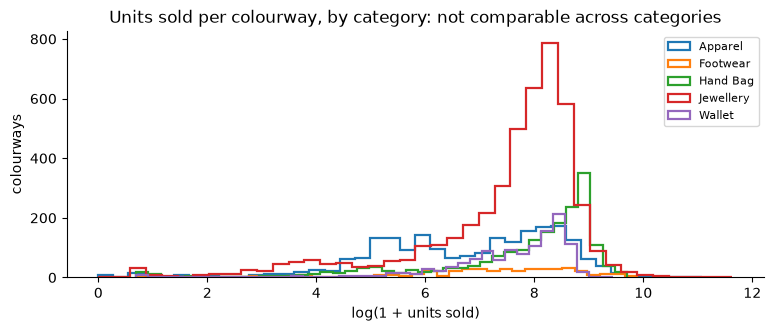

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for cat, grp in items.groupby("CAT_DES_EN"):
    ax.hist(np.log1p(grp["SALES_QTY"].dropna()), bins=40, histtype="step", linewidth=1.6, label=cat)
ax.set_xlabel("log(1 + units sold)")
ax.set_ylabel("colourways")
ax.set_title("Units sold per colourway, by category: not comparable across categories")
ax.legend(fontsize=8)
plt.show()

## 7. AI image audit (run once, results loaded here)

The rules above check file names, not what a photo shows. To find photos of the wrong product or colour, every photo
was processed **once**, on one laptop CPU (about 86 minutes for 9,457 photos), and the results were saved in
`data/embeddings/`. That step is not re-run here; this is what it did:

1. **Isolate the product**: crop the white background (pixel threshold); for photos that are not packshots (worn by
   a model, lifestyle), an object detector (OWLv2) finds the item.
2. **Encode the crop with CLIP** (ViT-B/32): 512 numbers per photo that describe what it shows. The same vectors are
   reused later as the visual feature for similarity.
3. **Zero-shot checks**: CLIP compares the photo with sentences such as *"a product photo of a necklace"* or
   *"... of a red item"*. A flag is raised when the item type or colour it sees disagrees with the data, when the
   photo is a near copy of another colour's photo, or when it is not a packshot.

Only the resulting flags are loaded:

In [15]:
VIS_SEVERITY = {"VIS_TYPE_MISMATCH": "high", "VIS_COLOUR_MISMATCH": "medium", "IMG_NEAR_DUPLICATE": "medium",
                "VIS_TYPE_DOUBT": "low", "VIS_TARGET_NOT_FOUND": "low", "IMG_NOT_PACKSHOT": "low"}
audit = pd.read_parquet(ROOT / "data" / "embeddings" / "image_audit.parquet", columns=[KEY, "vis_issues", "mask_method"])
vis = items[KEY].map(audit.set_index(KEY)["vis_issues"]).fillna("")
for c in VIS_SEVERITY:
    add_issue(vis.str.contains(c, regex=False), c)
print(f"photos audited: {len(audit):,} | product isolated by:", audit["mask_method"].value_counts().to_dict())
audit["vis_issues"].str.split(";").explode().loc[lambda s: s != ""].value_counts().rename("photos").to_frame()

photos audited: 9,490 | product isolated by: {'threshold': 9129, 'detector': 272, 'detector_refine': 89}


,photos
vis_issues,
IMG_NOT_PACKSHOT,272
VIS_TYPE_DOUBT,189
VIS_COLOUR_MISMATCH,135
IMG_NEAR_DUPLICATE,54
VIS_TARGET_NOT_FOUND,46
VIS_TYPE_MISMATCH,24


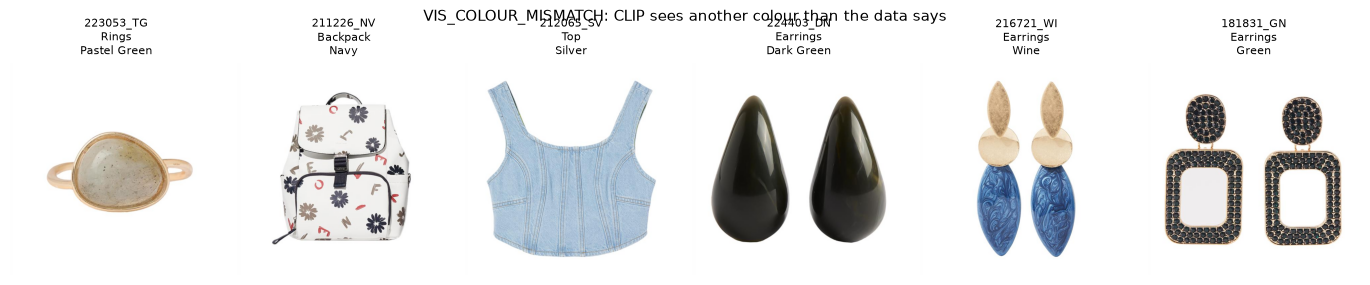

In [16]:
cm = items[items["issues"].str.contains("VIS_COLOUR_MISMATCH")]
show(cm[KEY].sample(6, random_state=0), "VIS_COLOUR_MISMATCH: CLIP sees another colour than the data says")

### 6–7 together: what was flagged

priority of each colourway (its most severe flag):
priority
high        29
medium     567
low        362
info       994
none      8603


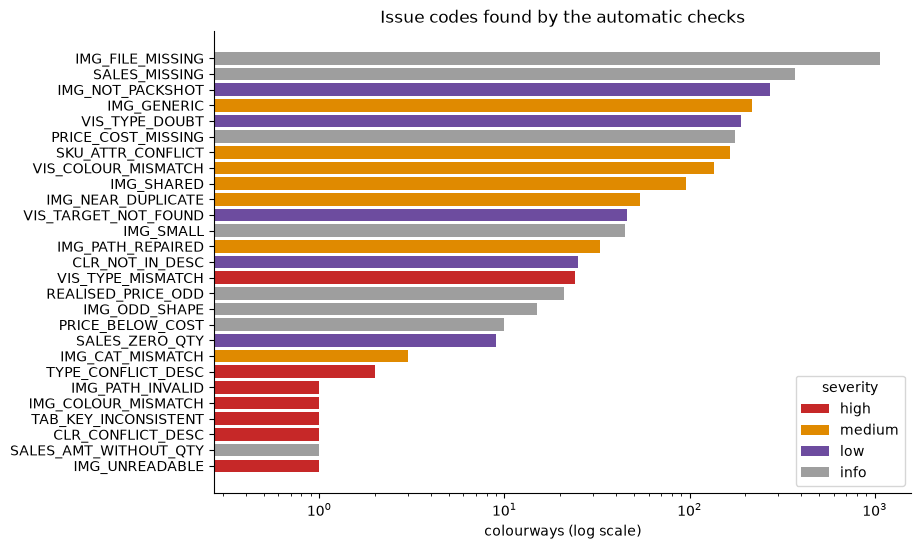

In [17]:
SEVERITY = {"IMG_PATH_INVALID": "high", "IMG_UNREADABLE": "high", "IMG_REF_MISMATCH": "high", "IMG_COLOUR_MISMATCH": "high",
            "TAB_KEY_INCONSISTENT": "high", "CLR_CODE_NAME_INCONSISTENT": "high", "CLR_CONFLICT_DESC": "high",
            "TYPE_CONFLICT_DESC": "high", "IMG_PATH_REPAIRED": "medium", "IMG_CAT_MISMATCH": "medium",
            "IMG_GENERIC": "medium", "IMG_SHARED": "medium", "SALES_NEGATIVE": "medium", "PRICE_INVALID": "medium",
            "SKU_ATTR_CONFLICT": "medium", "CLR_NOT_IN_DESC": "low", "SALES_ZERO_QTY": "low", "IMG_FILE_MISSING": "info",
            "SALES_MISSING": "info", "SALES_AMT_WITHOUT_QTY": "info", "REALISED_PRICE_ODD": "info",
            "PRICE_OUTLET_ABOVE_BASE": "info", "PRICE_COST_MISSING": "info", "PRICE_BELOW_COST": "info",
            "IMG_SMALL": "info", "IMG_ODD_SHAPE": "info", "IMG_NOT_RGB": "info", **VIS_SEVERITY}
RANK = {"high": 3, "medium": 2, "low": 1, "info": 0}
items["issues"] = items["issues"].str.rstrip(";")
items["priority"] = items["issues"].map(
    lambda s: max((RANK[SEVERITY[c]] for c in s.split(";") if c), default=-1)).map(
    {3: "high", 2: "medium", 1: "low", 0: "info", -1: "none"})
codes = items["issues"].str.split(";").explode().loc[lambda s: s != ""]
summary = codes.value_counts().rename("colourways").to_frame()
summary["severity"] = summary.index.map(SEVERITY)
print("priority of each colourway (its most severe flag):")
print(items["priority"].value_counts().reindex(["high", "medium", "low", "info", "none"]).to_string())

colour = {"high": "#c62828", "medium": "#e08a00", "low": "#6d4c9f", "info": "#9e9e9e"}
fig, ax = plt.subplots(figsize=(9, 6))
s = summary.iloc[::-1]
ax.barh(s.index, s["colourways"], color=s["severity"].map(colour))
ax.set_xscale("log")
ax.set_xlabel("colourways (log scale)")
ax.set_title("Issue codes found by the automatic checks")
for sev, col in colour.items():
    ax.bar(0, 0, color=col, label=sev)
ax.legend(title="severity", loc="lower right")
plt.show()

## 8. Manual review (described; its change log is applied)

The flags only point at possible problems; people decided. The 10,555 colourways were split into **five balanced
batches** (same category mix, all colours of a model in the same batch), one per team member, and reviewed in a
small browser app showing the photo, the description and the data side by side. For each colourway the reviewer chose:

| Decision | Meaning | What happens |
|---|---|---|
| Looks right | photo, description and data describe the same article | kept as is |
| Fix data | a value is wrong (colour, family, sub-family, finishing, material) | corrected; **only values that already exist in the data** could be chosen, so no new spelling enters |
| Wrong photo | the photo shows another product | photo unlinked; the item is matched on its data only |
| Not sure / Discard | decide together / remove | none were left at the end, no item was discarded |

The flagged items were reviewed first; in a second pass **every photo was checked**, flagged or not. The original
CSVs were never edited: every decision was saved, and the resulting changes are in `outputs/phase1/changes_log.csv`.

In [18]:
log = pd.read_csv(ROOT / "outputs" / "phase1" / "changes_log.csv", encoding="utf-8-sig", keep_default_na=False)
print(f"{len(log)} changes on {log[KEY].nunique()} colourways:", log["column"].value_counts().to_dict())
log[log["column"] == "CLR_DES"].groupby(["old", "new"]).size().sort_values(ascending=False).head(8).rename("changes").to_frame()

588 changes on 583 colourways: {'CLR_DES': 455, 'img_file': 122, 'GFA_DES_EN': 6, 'GFS_DES_EN': 4, 'FINISHING': 1}


changes
old    new                
Blue   Turquoise        28
       Teal             22
Pink   Fuchsia          15
Green  Teal             11
       Lime             11
Blue   Navy             10
       Light Blue        9
Purple Lilac             8

In [19]:
log[~log["column"].isin(["CLR_DES", "img_file"])][[KEY, "column", "old", "new"]]

,PROD_CLR_EQUIV,column,old,new
102,211159_GD,GFA_DES_EN,Earrings,Rings
103,211159_GD,GFS_DES_EN,Ear Cuff,Other Rings
104,211176_GD,GFA_DES_EN,Earrings,Rings
105,211176_GD,GFS_DES_EN,Ear Cuff,Other Rings
185,213986_SW,FINISHING,Golden,Other
303,218591_GD,GFA_DES_EN,Bracelets,Necklaces
304,218591_GD,GFS_DES_EN,Adjustable Bracelet,Beaded Necklace
313,218771_GN,GFA_DES_EN,Sweater,T-shirt
314,218771_NV,GFA_DES_EN,Sweater,T-shirt
344,219763_GD,GFA_DES_EN,Bracelets,Rings


Most fixes are colours that the data names too broadly (*Blue* for a turquoise item). Family fixes are items filed in
the wrong family (an ear cuff that is a ring). The decisions are applied to the table (the flags above stay as they were before the review: they
record why an item was looked at):

In [20]:
reviewed = items.set_index(KEY)
for r in log.itertuples(index=False):
    if r.column == "img_file":           # wrong photo: unlinked
        reviewed.at[r.PROD_CLR_EQUIV, "img_file"] = None
    else:
        reviewed.at[r.PROD_CLR_EQUIV, r.column] = r.new
reviewed["has_image"] = reviewed["img_file"].notna()

# the decision per colourway (needed to know which photos a person accepted)
batches = pd.concat([pd.read_csv(f, dtype=str, encoding="utf-8-sig", keep_default_na=False, usecols=[KEY, "review_status"])
                     for f in sorted((ROOT / "outputs" / "phase1" / "batches").glob("batch_*_of_05.csv"))])
reviewed["review_status"] = batches.set_index(KEY)["review_status"].replace("", "ok")
reviewed = reviewed.reset_index()
print(reviewed["review_status"].value_counts().to_string())
print(f"photos after the review: {reviewed['has_image'].sum():,}")

review_status
ok            9972
fix            461
drop_image     122
photos after the review: 9,445


## 9. Final cleaning

1. **Drop columns** that carry no information for similarity: empty or constant, exact copies of another column
   (Portuguese names, `*_ASIS`), and SKU-level columns (size, barcode) that mean nothing per colourway.
2. **Parse dates**, which come in three formats (`20230726`, `20230726.0`, ISO `2023-07-26 21:40:36`).
3. **Unify casing**: spellings that differ only in case get the most common one (`GOLDEN BASICS` → `Golden Basics`).
4. **Placeholders → missing**, per column only: `UNDEFINED` / `Not Applicable` (`DIMENSION`), `Without Block`,
   `Sem Categoria`. `Others` is kept: it is a real category in `PRINT_TYPE`, `GFA_DES_EN` and `FINISHING`.
5. **Sales features**: `has_sales`, `log_sales_qty`, `realised_price` (empty when 0 units) and
   `sales_pct_in_cat` (percentile **within the category**, since volumes differ so much between categories).
6. **Photo trust**: `img_trusted` (the photo shows this product) and `img_colour_trusted` (its colour is reliable
   too). A photo a reviewer accepted is trusted; otherwise the blocking flags decide.

In [21]:
EMPTY_OR_CONSTANT = miss.index[miss["status"].isin(["empty", "constant"])].tolist()
COPIES = {"CAT_DES_PT": "CAT_DES_EN", "GFA_DES_PT": "GFA_DES_EN", "GFS_DES_PT": "GFS_DES_EN",
          "PRICE_BASE_W_VAT_ASWAS": "PRICE_BASE_W_VAT", "WEEKS_TARGET": "ITEM_LIFE_CYCLE_WEEK",
          "FASHIONTYPE_ASIS": "FASHIONTYPE", "THEME_ASIS": "THEME", "THEME_CODE_ASIS": "THEME_CODE",
          "PROD_TYPOLOGY_ORIG_ASIS": "PROD_TYPOLOGY_ORIG", "PURCHASE_BET_ORIG_ASIS": "PURCHASE_BET_ORIG",
          "ONL_ENTRY_DATE": "ONL_ENTRY_DATE_DT", "ONL_IMAGE_DATE": "ONL_IMAGE_DATE_DT"}
SKU_LEVEL = ["PROD_SPK", "PROD_COD", "PROD_COD_EQUIV", "BAR_COD", "SZ_COD", "SZ_DES", "PROD_DES", "DESCRIPTION"]
WORK = ["img_stem", "img_md5"]
clean = reviewed.drop(columns=[c for c in EMPTY_OR_CONSTANT + list(COPIES) + SKU_LEVEL + WORK if c in reviewed])
print(f"columns: {reviewed.shape[1]} -> {clean.shape[1]}")

# the copies hold the same values (the two date pairs: same dates, written 20231003.0 vs 2023-10-03)
def as_text(s):
    s = s.astype("string").str.replace(r"\.0$", "", regex=True)
    if s.name.startswith("ONL_"):
        s = pd.to_datetime(s, format="mixed", errors="coerce").astype("string")
    return s.fillna("")
same = {c: float((as_text(prod[c]) == as_text(prod[o])).mean()) for c, o in COPIES.items() if c in prod}
print("share of rows where the copy equals the original:", {c: round(v, 3) for c, v in same.items()})

columns: 158 -> 103


share of rows where the copy equals the original: {'CAT_DES_PT': 1.0, 'GFA_DES_PT': 1.0, 'GFS_DES_PT': 1.0, 'PRICE_BASE_W_VAT_ASWAS': 1.0, 'WEEKS_TARGET': 1.0, 'FASHIONTYPE_ASIS': 1.0, 'THEME_ASIS': 1.0, 'THEME_CODE_ASIS': 1.0, 'PROD_TYPOLOGY_ORIG_ASIS': 1.0, 'PURCHASE_BET_ORIG_ASIS': 1.0, 'ONL_ENTRY_DATE': 1.0, 'ONL_IMAGE_DATE': 1.0}


In [22]:
DATE_COLS = ["STORE_DATE_FINAL", "STORE_DATE_PLANNED", "STORE_DATE_REAL", "STORE_DATE_REVISED", "STORE_DATE_OUTLET_REAL",
             "START_DATE", "ONL_ENTRY_DATE_DT", "ONL_IMAGE_DATE_DT", "ECI_ONLINE_DATE", "AUDIT_DT_INSERT"]

def parse_dates(s):
    text = s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    compact = text.str.fullmatch(r"\d{8}").fillna(False)
    out = pd.to_datetime(text.where(compact), format="%Y%m%d", errors="coerce")
    return out.fillna(pd.to_datetime(text.where(~compact), format="ISO8601", errors="coerce"))

lost = {}
for c in [c for c in DATE_COLS if c in clean]:
    before = clean[c].notna().sum()
    clean[c] = parse_dates(clean[c])
    lost[c] = int(before - clean[c].notna().sum())
print("date values that could not be parsed:", lost)
clean["OPACITY"] = clean["OPACITY"].replace({"Transluncent": "Translucent"})  # one typo

date values that could not be parsed: {'STORE_DATE_FINAL': 0, 'STORE_DATE_PLANNED': 0, 'STORE_DATE_REAL': 0, 'STORE_DATE_REVISED': 0, 'STORE_DATE_OUTLET_REAL': 0, 'START_DATE': 0, 'ONL_ENTRY_DATE_DT': 0, 'ONL_IMAGE_DATE_DT': 0, 'ECI_ONLINE_DATE': 0, 'AUDIT_DT_INSERT': 0}


In [23]:
NO_RECASE = {KEY, "PROD_CLR", "PROD_REF", "PROD_REF_EQUIV", "PROD_DES_BASE", "PROG_IMAGE", "img_file", "issues",
             "sku_conflicts", "refs_all", "sizes", "review_status"}

def unify_casing(s):
    v = s.dropna()
    if v.empty or not v.map(type).eq(str).all():
        return s, 0
    canon = {}
    for value, _ in sorted(v.value_counts().items(), key=lambda kv: (-kv[1], kv[0])):
        canon.setdefault(value.casefold(), value)
    new = v.str.casefold().map(canon)
    changed = new != v
    out = s.copy()
    out.loc[new.index[changed]] = new[changed]
    return out, int(changed.sum())

recased = {}
for c in [c for c in clean if c not in NO_RECASE and pd.api.types.is_string_dtype(clean[c])]:
    clean[c], k = unify_casing(clean[c])
    if k:
        recased[c] = k
print("values re-cased:", recased)
theme = reviewed["THEME"].dropna()
theme.groupby(theme.str.casefold()).agg(lambda s: sorted(set(s))).loc[lambda s: s.map(len) > 1].head(5).to_frame()

values re-cased: {'THEME': 153, 'DIMENSION': 4, 'GFS_DES_EN': 7, 'L4_DES': 2}


,THEME
THEME,
golden basics,"[GOLDEN BASICS, Golden Basics]"
lucy,"[LUCY, Lucy]"
neptune,"[NEPTUNE, Neptune]"
picasso,"[PICASSO, Picasso]"
t1 essentials,"[T1 ESSENTIALS, T1 essentials]"


In [24]:
PLACEHOLDERS = {"DIMENSION": {"not applicable", "undefined"}, "DISTRIBUTION_BLOCK": {"without block"},
                "CATEGORY_MATRIX": {"sem categoria"}, "CATEGORY_MATRIX_BUYER": {"sem categoria"}}
for col, values in PLACEHOLDERS.items():
    is_ph = clean[col].astype("string").str.casefold().isin(values).fillna(False)
    clean.loc[is_ph, col] = None
    print(f"{col}: {is_ph.sum():,} placeholders set to missing")

qty = clean["SALES_QTY"]
clean["has_sales"] = qty.notna()
clean["log_sales_qty"] = np.log1p(qty)
clean["realised_price"] = (clean["SALES_AMT_FX_RATE"] / qty).where(qty > 0)
clean["sales_pct_in_cat"] = clean.groupby("CAT_DES_EN")["SALES_QTY"].rank(pct=True)

BLOCKING = {"IMG_UNREADABLE", "IMG_REF_MISMATCH", "VIS_TYPE_MISMATCH"}          # shows another product / broken
COLOUR_BLOCKING = BLOCKING | {"IMG_COLOUR_MISMATCH", "IMG_NEAR_DUPLICATE", "VIS_COLOUR_MISMATCH", "IMG_SHARED",
                              "IMG_GENERIC"}                                    # shape fine, colour unreliable
flags = clean["issues"].str.split(";").map(set)
accepted = clean["review_status"].isin({"ok", "fix"})
clean["img_trusted"] = clean["has_image"] & (accepted | flags.map(BLOCKING.isdisjoint))
clean["img_colour_trusted"] = clean["has_image"] & (accepted | flags.map(COLOUR_BLOCKING.isdisjoint))
clean = clean.sort_values(KEY).reset_index(drop=True)
print(f"photos trusted: {clean['img_trusted'].sum():,} | colour also trusted: {clean['img_colour_trusted'].sum():,}")

DIMENSION: 7,168 placeholders set to missing
DISTRIBUTION_BLOCK: 9,896 placeholders set to missing
CATEGORY_MATRIX: 262 placeholders set to missing
CATEGORY_MATRIX_BUYER: 281 placeholders set to missing
photos trusted: 9,445 | colour also trusted: 9,445


## 10. The result

One row per colourway, every colourway kept, ready for feature extraction (Sprint 2).

In [25]:
assert clean[KEY].is_unique
assert len(clean) == raw_prod[KEY].nunique()
assert clean["SALES_QTY"].notna().sum() == len(raw_sales)
print(f"{clean.shape[0]:,} colourways x {clean.shape[1]} columns | checks passed: unique key, every colourway kept, "
      "every sales row joined")

overview = pd.DataFrame({
    "colourways": clean.groupby("CAT_DES_EN").size(),
    "families": clean.groupby("CAT_DES_EN")["GFA_DES_EN"].nunique(),
    "photo trusted": clean.groupby("CAT_DES_EN")["img_trusted"].mean().round(3),
    "with sales": clean.groupby("CAT_DES_EN")["has_sales"].mean().round(3),
    "median price €": clean.groupby("CAT_DES_EN")["PRICE_BASE_W_VAT"].median(),
})
overview.loc["total"] = [len(clean), clean["GFA_DES_EN"].nunique(), round(clean["img_trusted"].mean(), 3),
                         round(clean["has_sales"].mean(), 3), clean["PRICE_BASE_W_VAT"].median()]
overview.astype({"colourways": int, "families": int})

10,555 colourways x 109 columns | checks passed: unique key, every colourway kept, every sales row joined


,colourways,families,photo trusted,with sales,median price €
CAT_DES_EN,,,,,
Apparel,2259,25,0.827,0.922,32.99
Footwear,435,8,0.975,0.977,35.99
Hand Bag,1971,17,0.916,0.977,25.99
Jewellery,4639,10,0.896,0.977,7.99
Wallet,1251,7,0.952,0.975,15.99
total,10555,67,0.895,0.965,15.99


In [26]:
clean[[KEY, "PROD_DES_BASE", "CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN", "CLR_DES", "FINISHING", "COMPOSITION",
       "PRICE_BASE_W_VAT", "sales_pct_in_cat", "img_trusted", "img_colour_trusted"]].sample(6, random_state=7)

,PROD_CLR_EQUIV,PROD_DES_BASE,CAT_DES_EN,GFA_DES_EN,GFS_DES_EN,CLR_DES,FINISHING,COMPOSITION,PRICE_BASE_W_VAT,sales_pct_in_cat,img_trusted,img_colour_trusted
9217,224594_BK,Necklace Milagro Black,Jewellery,Necklaces,Beaded Necklace,Black,Other,Cork; Iron; Resin; Zinc,15.99,0.414626,True,True
3883,214811_BL,Backpack VIVIAN Blue,Hand Bag,Backpack,Plain PU,Blue,NaN,Polyester; Polyurethane; Zinc,23.99,0.847532,True,True
6594,219772_GD,Earring Golden Basics Gold,Jewellery,Earrings,Dangle,Gold,Multifinishing,Steel,5.99,0.698654,True,True
1435,210788_EC,Shoulder Bag SURFING Ecru,Hand Bag,Shoulder Bag,Padded Peach PU,Ecru,NaN,Polyester; Polyurethane,25.99,0.960519,True,True
6408,219412_BK,Shoulder Bag POPEYE3 Black,Hand Bag,Shoulder Bag,Plain PU,Black,Silver,Polyester; Polyurethane,29.99,0.597662,True,True
8012,222529_BM,Shirt 55 Bright Multicolor,Apparel,Shirt,Woven,Bright Multicolor,NaN,Cotton,23.99,0.251921,True,True


## Summary

| | |
|---|---|
| Raw data | 17,125 SKUs (one per size) and 10,185 sales rows |
| Unit of analysis | **10,555 colourways**, every one kept |
| Text | non-breaking spaces and padding removed, `COMPOSITION` canonical, casing unified, placeholders → missing |
| Columns | empty, constant, copied and SKU-level columns dropped |
| Photos | 89.9% of colourways linked (33 paths repaired); file checks + AI audit on every photo; every photo checked by a person |
| Review | 461 colourways fixed (mostly colours), 122 wrong photos unlinked, none discarded; 588 logged changes |

Principles: the original files are never modified; nothing is dropped or relabelled silently (a flag, a human
decision and a change log); every step is deterministic, so everyone gets the same table.